# Auction Pitch EDA: do Treasuries still cheapen into auctions?

**The mechanism.** The Treasury announces each coupon auction about a week ahead: size, tenor, date. The supply is
forced (it must be sold at whatever price clears) and lands on primary dealers, who have limited balance sheet. End
investors with imperfect capital mobility do not show up early to smooth it. So yields should **rise (prices fall) in
the days before an auction and fall back after it**, even though everything about the auction is public.

**The paper.** Lou, Yan & Zhang, *"Anticipated and Repeated Shocks in Liquid Markets"*, **Review of Financial Studies**
(2013): Treasury prices fall in the days before scheduled auctions and recover shortly after; they put the hidden
issuance cost at 9–18bp of auction size. Their sample ends before the post-2008 regulatory squeeze on dealer balance
sheets (SLR, Basel III) and before coupon issuance roughly doubled (2018–2026).

**Why it should be bigger now.** More supply per auction, less dealer capacity per dollar of supply. The opposite
force: the result is published, and anticipating it costs one futures trade.

**Questions.**
1. **Event study:** does the auctioned tenor's yield rise into the auction and fall after, relative to random days?
2. **Is it the auction?** Tenor-specific (the auctioned point moves vs the rest of the curve), bigger for bigger
   auctions, bigger when dealers take down more?
3. **Post-publication:** in-sample 1990–2013, out-of-sample 2014–2026.
4. **Tradable:** a duration-timing rule on Treasury ETFs (and its futures equivalent), after cost.

**Data** (all free): `auctions.csv` (TreasuryDirect: every note/bond auction since 1990, size, bidder shares;
`collect_auctions.py`), `yields.csv` (FRED constant-maturity yields), `etfs.csv` (SHY, IEI, IEF, TLH, TLT;
`collect_rates.py`).

**Realism rules**
* Auction dates are announced about a week ahead (and the quarterly/monthly calendar is fixed further out). Event
  windows start at most 5 trading days before the auction, inside what was public.
* Results come out at 13:00 ET; FRED yields and ETF closes are end-of-day, so day 0 (auction day) already contains the
  auction outcome. Pre-auction = closes of day −5 to day −1; the "auction day" is reported separately.
* Yields in bp; positive = cheapening (bad for a long bond position).

## 1. Data

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
DATA = Path("data")
SPLIT = pd.Timestamp("2014-01-01")          # paper published 2013: everything from 2014 is out-of-sample
W = 5                                       # event window: -W .. +W trading days

y = pd.read_csv(DATA / "yields.csv", parse_dates=["date"], index_col="date").dropna(how="all")
y = y[y.DGS10.notna()]
cal = y.index
dy = y.diff() * 100                          # bp
au = pd.read_csv(DATA / "auctions.csv", parse_dates=["auction_date", "announce_date", "issue_date"])
au = au[au.auction_date <= cal[-1]]
TENOR = {"2-Year": "DGS2", "3-Year": "DGS3", "5-Year": "DGS5", "7-Year": "DGS7", "10-Year": "DGS10", "20-Year": "DGS20", "30-Year": "DGS30"}
# term is the original term ("10-Year"); a few rows only carry the remaining term ("9-Year 10-Month"): round to the nearest tenor
yrs = au.term.str.extract(r"^(\d+)-Year")[0].astype(float) + au.term.str.extract(r"(\d+)-Month")[0].astype(float).fillna(0) / 12
std = np.array([2, 3, 5, 7, 10, 20, 30])
au["term0"] = [f"{std[np.abs(std - v).argmin()]}-Year" if v == v else None for v in yrs]
au["series"] = au.term0.map(TENOR)
au = au.dropna(subset=["series"])
au["i"] = cal.searchsorted(au.auction_date)                       # index of auction day in the calendar
au = au[(au.i >= W + 1) & (au.i < len(cal) - W)]
au = au[cal[au.i] == au.auction_date]                             # auction on a day with a FRED yield
au["is"] = au.auction_date < SPLIT
print(f"{len(au)} auctions, {au.auction_date.min().date()} .. {au.auction_date.max().date()}")
print(au.groupby(["term0", au.auction_date.dt.year // 10 * 10]).size().unstack().fillna(0).astype(int).to_string())

1984 auctions, 1989-12-19 .. 2026-09-24
auction_date  1980  1990  2000  2010  2020
term0                                     
10-Year          0    42    75   122    81
2-Year           1   116   119   111    80
20-Year          0     0     0     0    78
3-Year           1    38    30   119    81
30-Year          0    30    24   120    81
5-Year           0   104    94   120    80
7-Year           0    14    11   129    83


## 2. Event study: the auctioned tenor's yield around its auction
**What this does.** For every auction, the cumulative change in the auctioned tenor's yield from the close of day −6
(before the window) to the close of each day −5 … +5. Averaged across auctions, with 95% bands. The null is the same
path anchored on random non-auction days of the same tenor.

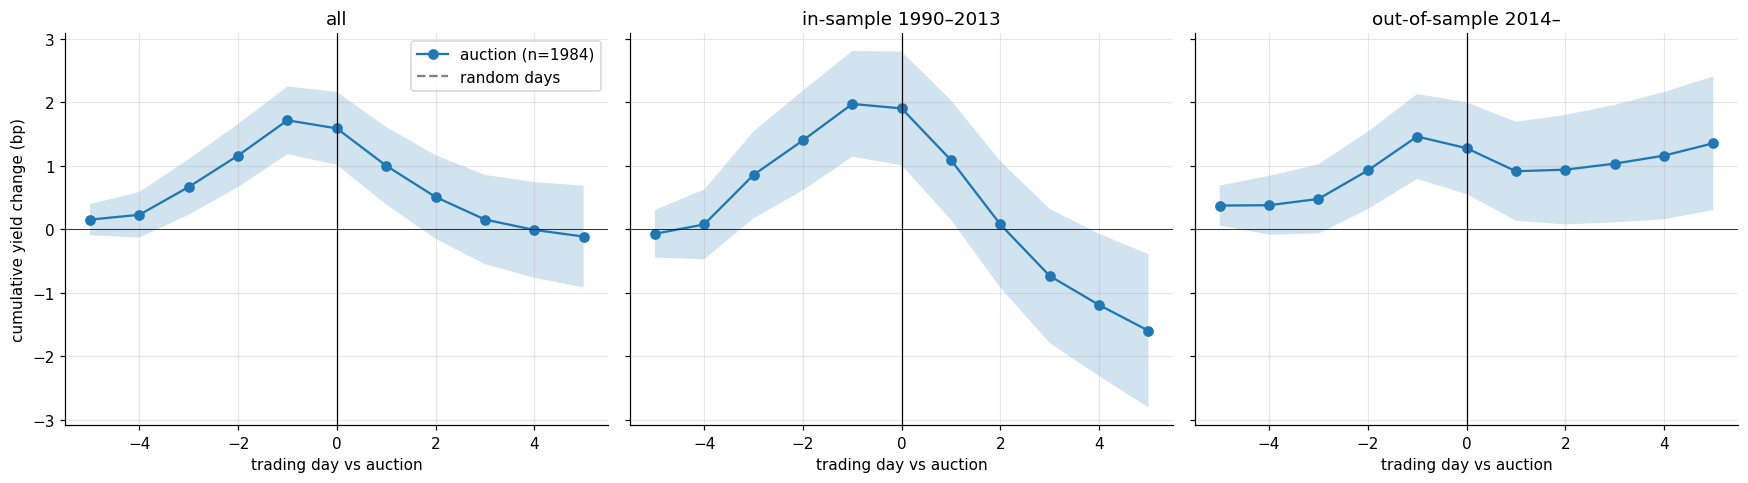

       sample                window  mean bp     t    n
          all        pre (-6 -> -1)     1.72  6.30 1984
          all auction day (-1 -> 0)    -0.13 -0.97 1984
          all        post (0 -> +5)    -1.70 -6.03 1984
          all        post (0 -> +2)    -1.08 -6.15 1984
    in-sample        pre (-6 -> -1)     1.97  4.64  987
    in-sample auction day (-1 -> 0)    -0.07 -0.34  987
    in-sample        post (0 -> +5)    -3.50 -8.34  987
    in-sample        post (0 -> +2)    -1.83 -6.95  987
out-of-sample        pre (-6 -> -1)     1.46  4.28  997
out-of-sample auction day (-1 -> 0)    -0.18 -1.13  997
out-of-sample        post (0 -> +5)     0.08  0.21  997
out-of-sample        post (0 -> +2)    -0.34 -1.47  997

random-day mean: pre -0.55bp, post +0.21bp (all years pooled)


In [2]:
Y = y.values * 100
cols = {c: j for j, c in enumerate(y.columns)}
def paths(idx, col):
    j = cols[col]
    base = Y[idx - W - 1, j]
    return np.column_stack([Y[idx + k, j] - base for k in range(-W, W + 1)])
P = np.vstack([paths(np.array([i]), s) for i, s in zip(au.i, au.series)])
au_paths = pd.DataFrame(P, index=au.index, columns=range(-W, W + 1))

rng = np.random.default_rng(0)
auction_days = set(zip(au.i, au.series))
null = []
for s in TENOR.values():
    ok = np.array([i for i in range(W + 1, len(cal) - W) if all((i + k, s) not in auction_days for k in range(-W, W + 1))])
    pick = rng.choice(ok, size=min(1000, len(ok)), replace=False)
    null.append(paths(pick, s))
null = np.vstack(null)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for a, (name, m) in zip(ax, [("all", au.index == au.index), ("in-sample 1990–2013", au["is"]), ("out-of-sample 2014–", ~au["is"])]):
    x = au_paths[m]
    a.plot(range(-W, W + 1), x.mean(), marker="o", label=f"auction (n={m.sum()})")
    a.fill_between(range(-W, W + 1), x.mean() - 1.96 * x.sem(), x.mean() + 1.96 * x.sem(), alpha=0.2)
    a.plot(range(-W, W + 1), null.mean(0), c="gray", ls="--", label="random days")
    a.axvline(0, c="k", lw=0.8); a.axhline(0, c="k", lw=0.5); a.set_title(name); a.set_xlabel("trading day vs auction")
ax[0].set_ylabel("cumulative yield change (bp)"); ax[0].legend()
plt.tight_layout(); plt.show()

def win(df, a, b):   # yield change from close of day a to close of day b
    return df[b] - (df[a] if a >= -W else 0)
rows = []
for name, m in [("all", au.index == au.index), ("in-sample", au["is"]), ("out-of-sample", ~au["is"])]:
    x = au_paths[m]
    for lab, (a, b) in {"pre (-6 -> -1)": (-W - 1, -1), "auction day (-1 -> 0)": (-1, 0), "post (0 -> +5)": (0, W), "post (0 -> +2)": (0, 2)}.items():
        v = win(x, a, b) if a >= -W else x[b]
        rows.append({"sample": name, "window": lab, "mean bp": v.mean(), "t": v.mean() / v.sem(), "n": len(v)})
print(pd.DataFrame(rows).round(2).to_string(index=False))
# random-day drift over the same windows, by period (rates trended down in-sample, up out-of-sample)
nd = pd.DataFrame(null, columns=range(-W, W + 1))
print(f"\nrandom-day mean: pre {nd[-1].mean():+.2f}bp, post {(nd[W] - nd[0]).mean():+.2f}bp (all years pooled)")

## 3. Is it the auction? Tenor-specific moves, size and dealer take-down
**What this does.**
* **Curve-relative:** the auctioned tenor's yield minus the average of the *other* tenors that have no auction in
  the window. If dealers are warehousing supply at one point of the curve, that point should cheapen relative to
  the rest, which also strips out macro news that moves the whole curve.
* **Size:** offering amount scaled by the tenor's average size in the trailing 3 years (so the doubling of issuance
  is not mistaken for a trend). Bigger-than-usual auctions should show a bigger cycle.
* **Dealer take-down:** primary dealer share of the auction (known only after; used to check the mechanism, not to
  trade).

In [3]:
busy = {}
for i, s in zip(au.i, au.series):
    for k in range(-W - 1, W + 1):
        busy.setdefault(i + k, set()).add(s)
def rel_path(i, s):
    others = [c for c in TENOR.values() if c != s and c not in busy.get(i, set()) and not np.isnan(Y[i, cols[c]])]
    if not others:
        return np.full(2 * W + 1, np.nan)
    own = paths(np.array([i]), s)[0]
    oth = np.mean([paths(np.array([i]), c)[0] for c in others], axis=0)
    return own - oth
R = pd.DataFrame(np.vstack([rel_path(i, s) for i, s in zip(au.i, au.series)]), index=au.index, columns=range(-W, W + 1))
au["pre"] = au_paths[-1]                        # close -6 -> close -1
au["day0"] = au_paths[0] - au_paths[-1]
au["post"] = au_paths[W] - au_paths[0]
au["pre_rel"] = R[-1]; au["post_rel"] = R[W] - R[0]
for name, m in [("in-sample", au["is"]), ("out-of-sample", ~au["is"])]:
    x = au[m]
    print(f"{name:14s} curve-relative: pre {x.pre_rel.mean():+.2f}bp (t {x.pre_rel.mean() / x.pre_rel.sem():+.1f}, n={x.pre_rel.notna().sum()}), "
          f"post {x.post_rel.mean():+.2f}bp (t {x.post_rel.mean() / x.post_rel.sem():+.1f})")

au = au.sort_values("auction_date")
au["size_rel"] = au.offering / au.groupby("term0").offering.transform(lambda s: s.rolling(12, min_periods=3).mean().shift(1))
au["size_q"] = pd.qcut(au.size_rel.rank(method="first"), 3, labels=["small", "normal", "big"])
au["dealer_q"] = au.groupby(au.auction_date.dt.year).dealer_share.transform(lambda s: pd.qcut(s.rank(method="first"), 3, labels=False) + 1 if s.notna().sum() >= 6 else np.nan)
print("\nby relative size (all years): mean bp")
print(au.groupby("size_q", observed=True)[["pre", "day0", "post"]].mean().round(2).to_string())
print("\nby dealer take-down tercile within year (1 = least, 3 = most):")
print(au.groupby("dealer_q")[["pre", "day0", "post"]].mean().round(2).to_string())
print("\nby tenor (out-of-sample):")
print(au[~au["is"]].groupby("term0")[["pre", "day0", "post"]].agg(["mean"]).round(2).droplevel(1, axis=1).assign(n=au[~au["is"]].groupby("term0").size()).to_string())

in-sample      curve-relative: pre +1.26bp (t +7.1, n=987), post -0.89bp (t -5.1)
out-of-sample  curve-relative: pre +0.35bp (t +2.4, n=989), post -0.20bp (t -1.3)

by relative size (all years): mean bp
         pre  day0  post
size_q                  
small   1.99  0.20 -0.49
normal  1.38 -0.33 -0.98
big     1.61 -0.14 -3.66

by dealer take-down tercile within year (1 = least, 3 = most):
           pre  day0  post
dealer_q                  
1.0       1.55 -1.00 -0.72
2.0       1.34  0.11 -0.52
3.0       2.78  1.49 -1.82

by tenor (out-of-sample):
          pre  day0  post    n
term0                         
10-Year  2.06  0.16  1.03  155
2-Year   2.41 -1.23 -0.40  143
20-Year  1.40 -1.10  1.06   78
3-Year   1.72  0.15  2.28  152
30-Year  1.83  0.46  0.46  153
5-Year   1.38  0.11 -1.81  154
7-Year  -0.43 -0.35 -1.52  162


## 4. Stability: by era and by year
**What this does.** Pre-auction cheapening (close −6 → close −1) and post-auction richening (close 0 → close +5), by
5-year era and by year, with t-stats. The paper's result should be visible in 1990–2008, and the question is
what happened after the dealer-capacity squeeze and after publication.

         n   pre  t_pre  post  t_post  pre_rel  post_rel
era                                                     
90-95  221  2.14   2.13 -4.71   -5.27     1.11     -0.57
96-01  168  2.29   2.34 -1.09   -1.07     0.76     -0.21
02-07  197 -0.25  -0.28 -3.65   -4.10     0.41     -0.87
08-13  399  2.87   4.45 -3.88   -5.82     1.96     -1.38
14-19  433  0.75   1.78 -0.89   -2.19     0.62     -0.90
20-26  564  2.01   3.94  0.82    1.43     0.14      0.36


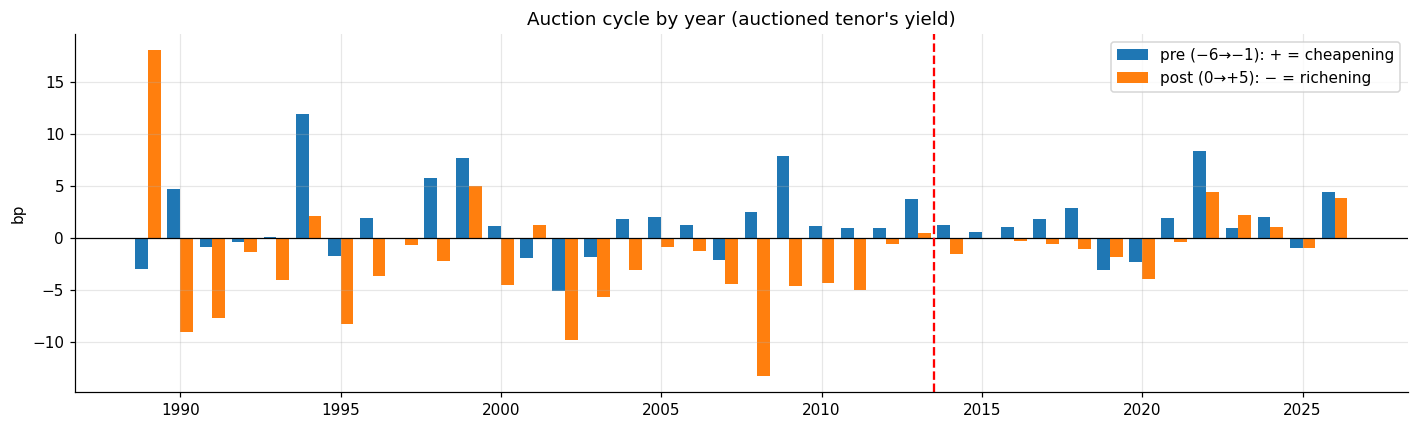

In [4]:
au["era"] = pd.cut(au.auction_date.dt.year, [1989, 1995, 2001, 2007, 2013, 2019, 2026], labels=["90-95", "96-01", "02-07", "08-13", "14-19", "20-26"])
g = au.groupby("era", observed=True)
tab = pd.DataFrame({"n": g.size(), "pre": g.pre.mean(), "t_pre": g.pre.mean() / g.pre.sem(),
                    "post": g.post.mean(), "t_post": g.post.mean() / g.post.sem(),
                    "pre_rel": g.pre_rel.mean(), "post_rel": g.post_rel.mean()})
print(tab.round(2).to_string())
yr = au.groupby(au.auction_date.dt.year)[["pre", "post"]].mean()
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(yr.index - 0.2, yr.pre, width=0.4, label="pre (−6→−1): + = cheapening")
ax.bar(yr.index + 0.2, yr.post, width=0.4, label="post (0→+5): − = richening")
ax.axhline(0, c="k", lw=0.8); ax.axvline(2013.5, c="r", ls="--"); ax.legend(); ax.set_ylabel("bp")
ax.set_title("Auction cycle by year (auctioned tenor's yield)"); plt.tight_layout(); plt.show()

## 5. A daily-calendar version (what a duration trader sees)
**What this does.** Not every day is around exactly one auction, so build a daily signal on the calendar: for each
trading day, the number of upcoming coupon auctions in the next 1–5 days ("pre" days) and of auctions in the last
0–4 days ("post" days), weighted by the auction's 10-year duration-equivalent size (offering × duration / 10y
duration). Then regress the next-day change in the 10-year yield, and in a duration-matched ETF return, on the
calendar position. Everything on the right-hand side is known from the announced calendar.

In [5]:
DUR = {"DGS2": 1.9, "DGS3": 2.8, "DGS5": 4.6, "DGS7": 6.3, "DGS10": 8.5, "DGS20": 14.0, "DGS30": 18.0}
au["dv01"] = au.offering * au.series.map(DUR) / 8.5 / 1e9          # 10y-equivalent $bn
n = len(cal)
pre_w = np.zeros(n); post_w = np.zeros(n)
for i, w in zip(au.i, au.dv01):
    for k in range(1, W + 1):          # day i-k is k days before the auction: its NEXT day return is still pre-auction if k >= 2
        if i - k >= 0: pre_w[i - k] += w
    for k in range(0, W):              # auction day and the 4 days after
        if i + k < n: post_w[i + k] += w
D = pd.DataFrame({"pre_w": pre_w, "post_w": post_w}, index=cal)
D["dy10_next"] = dy.DGS10.shift(-1).reindex(cal)
D["dy_avg_next"] = dy[["DGS2", "DGS5", "DGS10", "DGS30"]].mean(1).shift(-1).reindex(cal)
D["is"] = D.index < SPLIT
for name, m in [("in-sample", D["is"]), ("out-of-sample", ~D["is"])]:
    d = D[m].dropna()
    f = sm.OLS(d.dy_avg_next, sm.add_constant(d[["pre_w", "post_w"]])).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    print(f"{name:14s} next-day avg yield change (bp) per $10bn 10y-equiv: pre {f.params.pre_w * 10:+.3f} (t {f.tvalues.pre_w:+.1f}), "
          f"post {f.params.post_w * 10:+.3f} (t {f.tvalues.post_w:+.1f})")

in-sample      next-day avg yield change (bp) per $10bn 10y-equiv: pre +0.144 (t +3.5), post -0.149 (t -3.8)
out-of-sample  next-day avg yield change (bp) per $10bn 10y-equiv: pre +0.061 (t +2.2), post +0.024 (t +0.9)


## 6. Tradable version on ETFs
**Rule.** Duration timing with one fixed calendar: hold **short** duration on days whose next close is inside a
pre-auction window (days −5 … −1 of any coupon auction), **long** duration in post-auction windows (days 0 … +4), flat
otherwise; when both apply, net them by size. Implemented with IEF (7–10y) and TLT (20y+), and as a curve-neutral
version (IEF minus duration-matched SHY) to strip out the level of rates. Returns are total-return ETF returns; cost
1bp per unit of turnover (ETF spreads are about 1bp; the futures version is cheaper).

                                           mean bp/day  ann. ret %  Sharpe     t  days in market
IEF                   in-sample 2002–13           2.28        5.74    0.84  2.85            0.91
                      out-of-sample 2014–         0.03        0.07    0.01  0.04            0.98
TLT                   in-sample 2002–13           4.97       12.52    0.93  3.15            0.92
                      out-of-sample 2014–         0.12        0.29    0.02  0.07            0.99
IEF - 2.3xSHY (curve) in-sample 2002–13           0.87        2.18    0.45  1.54            0.92
                      out-of-sample 2014–        -0.62       -1.56   -0.37 -1.33            0.99


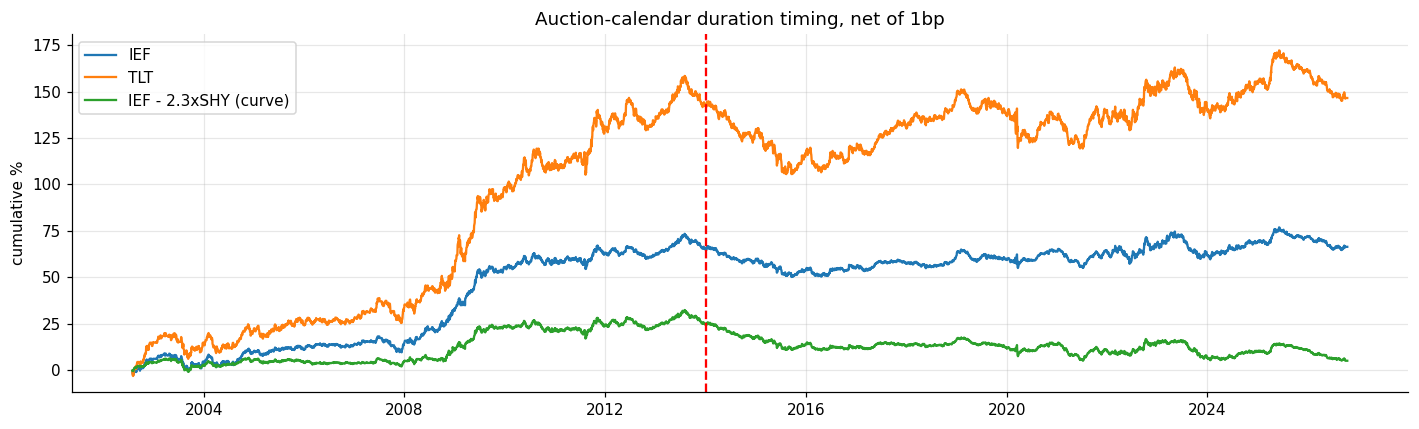


buy-and-hold IEF Sharpe for reference: 0.53


In [6]:
e = pd.read_csv(DATA / "etfs.csv", parse_dates=["date"]).pivot(index="date", columns="ticker", values="adj_close")
r = e.pct_change() * 1e4                       # bp
sig = np.sign(D.post_w - D.pre_w)               # +1 long duration, -1 short, 0 flat; known at the close of day t
pos = sig.reindex(r.index).fillna(0)
COST = 1.0
def run(ret, pos, cost=COST):
    pnl = pos.shift(1) * ret - cost * pos.diff().abs().fillna(0)
    return pnl.dropna()
def summ(p):
    return pd.Series({"mean bp/day": p.mean(), "ann. ret %": p.mean() * 252 / 100, "Sharpe": p.mean() / p.std() * np.sqrt(252),
                      "t": p.mean() / p.std() * np.sqrt(len(p)), "days in market": (p != 0).mean()})
strat = {"IEF": run(r.IEF, pos), "TLT": run(r.TLT, pos), "IEF - 2.3xSHY (curve)": run(r.IEF - 2.3 * r.SHY, pos)}
out = {}
for k, p in strat.items():
    out[(k, "in-sample 2002–13")] = summ(p[p.index < SPLIT]); out[(k, "out-of-sample 2014–")] = summ(p[p.index >= SPLIT])
print(pd.DataFrame(out).T.round(2).to_string())
fig, ax = plt.subplots(figsize=(13, 4))
for k, p in strat.items():
    ax.plot(p.cumsum() / 100, label=k)
ax.axvline(SPLIT, c="r", ls="--"); ax.legend(); ax.set_ylabel("cumulative %"); ax.set_title("Auction-calendar duration timing, net of 1bp")
plt.tight_layout(); plt.show()
print("\nbuy-and-hold IEF Sharpe for reference:", round(r.IEF.mean() / r.IEF.std() * np.sqrt(252), 2))

**Interpretation.**
- **The netted rule does nothing out-of-sample** (IEF Sharpe 0.01, TLT 0.02). It is in the market 98% of the time,
  and half of that is the post-auction long, which died after 2013 (§2). The edge has to be isolated to the pre-auction leg.

## 7. The pre-auction short on its own
**Rule.** For each coupon auction, short the auctioned tenor (equal DV01: one unit of yield risk per leg) from the
close of day −6 to the close of day −1, then flat; exit before the 13:00 auction. Several auctions can overlap
(2y/5y/7y in one week), so up to three legs run at once. P&L in yield bp per unit DV01 (a short earns $+\Delta y$).
Implement with Treasury futures (ZT/ZF/ZN/TN/ZB/UB): cost 0.25bp of yield per round trip (about half a tick each side).

**The rate-drift problem.** The strategy is short duration 46% of days in-sample and 73% out-of-sample (more auctions
per month), and 2014–2026 was a decade of rising yields. So part of the raw P&L is just being short in a selloff.
Fix: hedge with a constant long-duration position sized by a **rolling 3-year beta to the average curve move,
estimated only on past data**, and report what is left.

**Placebo.** Shift every pre-auction window by ±7, ±10, ±15 trading days. Caveat: the calendar is dense (mid-month
3/10/30y, end-month 2/5/7y, 20y in between), so a ±10-day shift lands on *another* cluster's pre-window, and −15 lands
on post-auction windows. Not every shift is a clean null.

share of days with a pre-auction leg: in-sample 46%, out-of-sample 73%
in-sample      daily yield change on pre-auction days +0.406bp vs other days -0.173bp: diff +0.580 (t +6.35)
out-of-sample  daily yield change on pre-auction days +0.312bp vs other days +0.027bp: diff +0.285 (t +3.43)
2020-          daily yield change on pre-auction days +0.411bp vs other days +0.125bp: diff +0.285 (t +2.24)


 cost bp              period  raw Sharpe  hedged bp/yr  hedged Sharpe    t
    0.00 in-sample 1993–2013        0.75        102.07           1.11 5.05
    0.00 out-of-sample 2014–        0.80         82.83           0.86 3.05
    0.00             2014–19        0.57         72.70           0.96 2.34
    0.00               2020–        0.95         91.80           0.82 2.13
    0.00         OOS ex-2022        0.49         65.70           0.73 2.48
    0.25 in-sample 1993–2013        0.67         91.74           0.99 4.54
    0.25 out-of-sample 2014–        0.67         63.56           0.66 2.34
    0.25             2014–19        0.41         55.11           0.73 1.77
    0.25               2020–        0.84         71.04           0.63 1.64
    0.25         OOS ex-2022        0.36         46.58           0.51 1.76
    0.50 in-sample 1993–2013        0.58         81.41           0.88 4.03
    0.50 out-of-sample 2014–        0.54         44.29           0.46 1.63
    0.50             2014

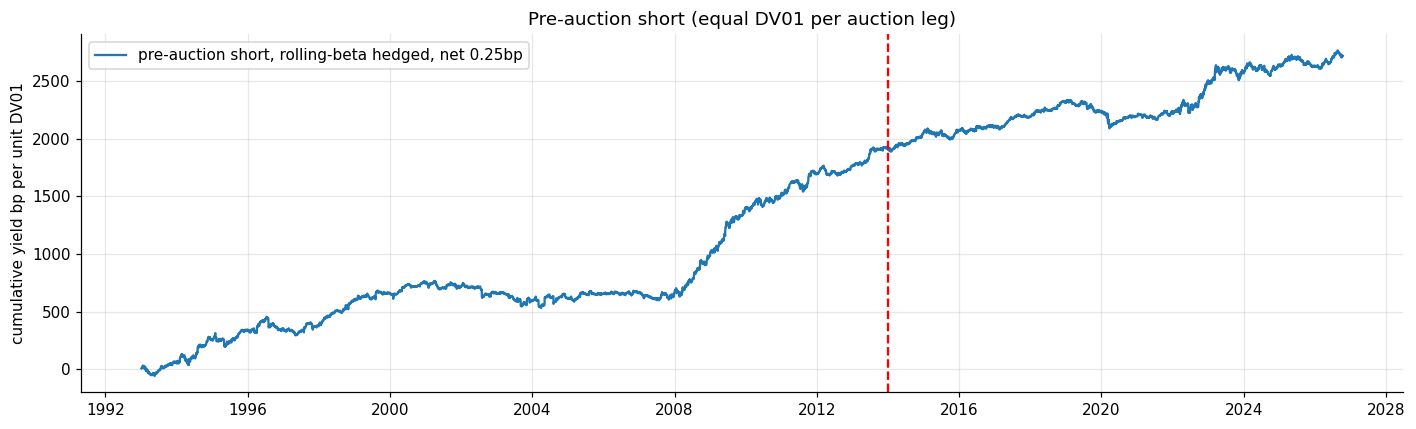

by year (hedged, net): {2014: 139, 2015: 22, 2016: 36, 2017: 82, 2018: 132, 2019: -84, 2020: -47, 2021: 41, 2022: 261, 2023: 75, 2024: 61, 2025: -4, 2026: 91}

calendar-shift placebo, out-of-sample alpha vs the average curve move (net 0.25bp):
  shift -15 days: alpha  -94.3bp/yr (t -3.48)


  shift -10 days: alpha  +56.0bp/yr (t +2.11)
  shift  -7 days: alpha  -32.1bp/yr (t -1.12)
  shift  +0 days: alpha  +67.4bp/yr (t +2.57)
  shift  +7 days: alpha  -23.8bp/yr (t -0.92)
  shift +10 days: alpha   +0.8bp/yr (t +0.03)
  shift +15 days: alpha   -6.3bp/yr (t -0.23)


In [7]:
tl = list(TENOR.values()); n = len(cal)
DY = dy[tl].reindex(cal)
mk = DY.mean(1).fillna(0)
def legs(shift=0):
    L = np.zeros((n, len(tl)))
    for i, s in zip(au.i, au.series):
        for k in range(-W, 0):                       # returns of days -5..-1 = close -6 -> close -1
            j = i + k + shift
            if 0 <= j < n: L[j, tl.index(s)] = 1
    return pd.DataFrame(L, index=cal, columns=tl)
def strat(A, c=0.25):
    return (A * DY).fillna(0).sum(1) - c * (A.diff().fillna(A) > 0).sum(1)
act = legs()
print(f"share of days with a pre-auction leg: in-sample {(act[cal < SPLIT].sum(1) > 0).mean():.0%}, out-of-sample {(act[cal >= SPLIT].sum(1) > 0).mean():.0%}")

DYa, Oth = DY.values, act.values
for per, m in [("in-sample", cal < SPLIT), ("out-of-sample", cal >= SPLIT), ("2020-", cal >= "2020-01-01")]:
    a = DYa[m][Oth[m] == 1]; b = DYa[m][Oth[m] == 0]; a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    t, _ = stats.ttest_ind(a, b, equal_var=False)
    print(f"{per:14s} daily yield change on pre-auction days {a.mean():+.3f}bp vs other days {b.mean():+.3f}bp: diff {a.mean() - b.mean():+.3f} (t {t:+.2f})")

rows = []
for c in [0, 0.25, 0.5]:
    pn = strat(act, c)
    roll_b = pd.Series(np.nan, index=cal)
    for d in pd.date_range("1993-01-01", cal[-1], freq="YS"):
        m = (cal >= d - pd.DateOffset(years=3)) & (cal < d)
        roll_b[(cal >= d) & (cal < d + pd.DateOffset(years=1))] = sm.OLS(pn[m], sm.add_constant(mk[m])).fit().params.iloc[1]
    h = (pn - roll_b * mk).dropna()
    for per, m in [("in-sample 1993–2013", h.index < SPLIT), ("out-of-sample 2014–", h.index >= SPLIT),
                   ("2014–19", (h.index >= SPLIT) & (h.index < "2020-01-01")), ("2020–", h.index >= "2020-01-01"),
                   ("OOS ex-2022", (h.index >= SPLIT) & (h.index.year != 2022))]:
        x, r_ = h[m], pn.reindex(h.index)[m]
        rows.append({"cost bp": c, "period": per, "raw Sharpe": r_.mean() / r_.std() * np.sqrt(252),
                     "hedged bp/yr": x.mean() * 252, "hedged Sharpe": x.mean() / x.std() * np.sqrt(252), "t": x.mean() / x.std() * np.sqrt(len(x))})
    if c == 0.25:
        H = h
print(pd.DataFrame(rows).round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(H.cumsum(), label="pre-auction short, rolling-beta hedged, net 0.25bp")
ax.axvline(SPLIT, c="r", ls="--"); ax.set_ylabel("cumulative yield bp per unit DV01"); ax.legend()
ax.set_title("Pre-auction short (equal DV01 per auction leg)"); plt.tight_layout(); plt.show()
print("by year (hedged, net):", H.groupby(H.index.year).sum().round(0).loc[2014:].astype(int).to_dict())

print("\ncalendar-shift placebo, out-of-sample alpha vs the average curve move (net 0.25bp):")
for sh in [-15, -10, -7, 0, 7, 10, 15]:
    p2 = strat(legs(sh)); m = cal >= SPLIT
    f = sm.OLS(p2[m], sm.add_constant(mk[m])).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    print(f"  shift {sh:+3d} days: alpha {f.params.const * 252:+6.1f}bp/yr (t {f.tvalues.const:+.2f})")

**Interpretation.**
- **Pre-auction days are still different.** Out of sample, the auctioned tenor's yield rises +0.31bp/day on
  pre-auction days against +0.03bp on other days (difference t = +3.4). The difference is half its in-sample size
  (+0.58bp/day) but clearly alive.
- **Tradable after the drift hedge and costs, modestly.** Hedged with a past-only rolling beta and net of 0.25bp per
  round trip: out-of-sample about +64bp/yr per unit DV01, Sharpe ≈ 0.66, t ≈ 2.3. Both halves are positive
  (2014–19 and 2020–). 9 of 13 years are positive, the best being 2022 (+261bp), a year of heavy supply and weak
  dealer capacity. **Without 2022 it drops to Sharpe ≈ 0.5 (t ≈ 1.8).**
- **Cost sensitivity is real.** At 0.5bp per round trip the out-of-sample alpha roughly halves. Futures at about half
  a tick is realistic for small size; ETFs would be worse.
- **The placebo is consistent with the auction calendar rather than against it.** Shifts of ±7, +10 and +15 days give
  nothing (|t| ≤ 1.1). The −10 shift lands on the other auction cluster's pre-window (positive, t ≈ 2.1). The −15
  shift lands on post-auction days (negative, t ≈ −3.5), so some post-auction richening survives in aggregate even
  though the per-tenor 5-day post window (§2) does not.

## 8. Look-ahead check: was the auction known at entry?
**What this does.** The rule above enters at the close of day −6. The Treasury's formal auction announcement comes a
median of **4** trading days before the auction, and for about 94% of auctions it comes *after* that entry. The dates
are often guessable (regular calendar, quarterly tentative schedules), but that cannot be verified across 1990–2026,
so the strict version only enters at the close of the announcement day or later. The "last 2 days" row is a variant
tried *after* seeing results and is shown only for transparency, not as evidence.

In [8]:
au["ia"] = cal.searchsorted(au.announce_date)
lead = au.i - au.ia
print(f"announcement lead (trading days): median {lead.median():.0f}; announced after the day -6 entry: {(lead < 6).mean():.0%}")
def legs_s(strict, first=-W, last=-1):
    L = np.zeros((n, len(tl)))
    for i, s, ia in zip(au.i, au.series, au.ia):
        start = max(i + first, ia + 1) if strict else i + first
        for j in range(start, i + last + 1):
            L[j, tl.index(s)] = 1
    return pd.DataFrame(L, index=cal, columns=tl)
def hedge(pn):
    rb = pd.Series(np.nan, index=cal)
    for d in pd.date_range("1993-01-01", cal[-1], freq="YS"):
        m = (cal >= d - pd.DateOffset(years=3)) & (cal < d)
        rb[(cal >= d) & (cal < d + pd.DateOffset(years=1))] = sm.OLS(pn[m], sm.add_constant(mk[m])).fit().params.iloc[1]
    return (pn - rb * mk).dropna()
rows = []
for name, A in [("entry close -6 (LOOK-AHEAD)", legs_s(False)), ("strict: entry at announcement close", legs_s(True)),
                ("strict, held through auction day", legs_s(True, last=0)), ("strict, last 2 days only (post-hoc)", legs_s(True, first=-2))]:
    h = hedge(strat(A, 0.25))
    for per, m in [("in-sample", h.index < SPLIT), ("out-of-sample", h.index >= SPLIT)]:
        x = h[m]
        rows.append({"version": name, "period": per, "Sharpe": x.mean() / x.std() * np.sqrt(252), "t": x.mean() / x.std() * np.sqrt(len(x))})
print(pd.DataFrame(rows).round(2).to_string(index=False))

announcement lead (trading days): median 4; announced after the day -6 entry: 94%


                            version        period  Sharpe    t
        entry close -6 (LOOK-AHEAD)     in-sample    0.99 4.54
        entry close -6 (LOOK-AHEAD) out-of-sample    0.66 2.34
strict: entry at announcement close     in-sample    0.66 2.99
strict: entry at announcement close out-of-sample    0.28 1.01
   strict, held through auction day     in-sample    0.64 2.90
   strict, held through auction day out-of-sample    0.06 0.23
strict, last 2 days only (post-hoc)     in-sample    0.60 2.72
strict, last 2 days only (post-hoc) out-of-sample    0.59 2.12


**Interpretation.**
- **The tradable result in §7 depended on look-ahead.** Entering only once the auction is formally announced,
  the out-of-sample Sharpe (drift-hedged, net 0.25bp) falls from 0.66 to about 0.28 (t ≈ 1.0). Holding through the
  auction day makes it worse.
- **A second, softer bias:** focusing on the pre-auction leg was decided after seeing that the post-auction leg died
  out of sample.
- The cheapening in the event study (§2) is real, but most of it happens before the formal announcement, i.e. in
  days a strict trader cannot be sure about.

## 9. Takeaways

| question | answer |
|---|---|
| Does the auctioned tenor cheapen into the auction? | **Yes, in both samples.** Close −6 → −1: +1.97bp in-sample (t 4.6), +1.46bp out-of-sample (t 4.3), vs a +0.45bp drift. |
| Does it richen after? | **In-sample yes (−3.5bp, t −8.3), out-of-sample no (+0.1bp).** The post-auction half of the paper is gone. |
| Is it the auction? | Curve-relative cheapening survives OOS (+0.35bp, t 2.4) but is small. It is biggest when dealers take down the most (+2.8bp pre in the top tercile). |
| Stability | Weak in 2002–07 and 2014–19, strong in 2008–13 and **2020–26 (+2.0bp, t 3.9)**, the era of heavy issuance and constrained dealers. |
| Tradable | Netted ETF rule: **no**. Pre-auction futures short: Sharpe 0.66 OOS **only with look-ahead** (entry before the formal announcement); strict entry at the announcement: **Sharpe ≈ 0.28, t ≈ 1.0. Fails.** |

**Verdict: fails once look-ahead is removed.** The supply-driven cheapening into auctions survived publication
in the event study, and it is strongest in the heavy-issuance 2020s. But a trader who acts only after the formal
announcement captures too little of it to clear costs out of sample. Worth revisiting only with proof that the
tentative quarterly calendar fixed the dates in advance (then the day −6 entry is legitimate), or with intraday
data (announcement at 11:00, auction at 13:00).